In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('./data/PhiUSIIL_Phishing_URL_Dataset.csv')
display(df.head())

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [3]:
display(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               235795 non-null  int64  
 13  HasObfuscation

None

In [4]:
print("Dataset shape:", df.shape)
print("Dataset info:")
print(df.info())

Dataset shape: (235795, 56)
Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 56 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   FILENAME                    235795 non-null  object 
 1   URL                         235795 non-null  object 
 2   URLLength                   235795 non-null  int64  
 3   Domain                      235795 non-null  object 
 4   DomainLength                235795 non-null  int64  
 5   IsDomainIP                  235795 non-null  int64  
 6   TLD                         235795 non-null  object 
 7   URLSimilarityIndex          235795 non-null  float64
 8   CharContinuationRate        235795 non-null  float64
 9   TLDLegitimateProb           235795 non-null  float64
 10  URLCharProb                 235795 non-null  float64
 11  TLDLength                   235795 non-null  int64  
 12  NoOfSubDomain               23

In [5]:
for i, col in enumerate(df.columns, 1):

    print(f"\n{i}. {col}")

    print("Data type:", df[col].dtype)

    print("Unique values:", df[col].nunique())

    print("Sample values:")
    print(df[col].drop_duplicates().head(5).tolist())


1. FILENAME
Data type: object
Unique values: 235795
Sample values:
['521848.txt', '31372.txt', '597387.txt', '554095.txt', '151578.txt']

2. URL
Data type: object
Unique values: 235370
Sample values:
['https://www.southbankmosaics.com', 'https://www.uni-mainz.de', 'https://www.voicefmradio.co.uk', 'https://www.sfnmjournal.com', 'https://www.rewildingargentina.org']

3. URLLength
Data type: int64
Unique values: 482
Sample values:
[31, 23, 29, 26, 33]

4. Domain
Data type: object
Unique values: 220086
Sample values:
['www.southbankmosaics.com', 'www.uni-mainz.de', 'www.voicefmradio.co.uk', 'www.sfnmjournal.com', 'www.rewildingargentina.org']

5. DomainLength
Data type: int64
Unique values: 101
Sample values:
[24, 16, 22, 19, 26]

6. IsDomainIP
Data type: int64
Unique values: 2
Sample values:
[0, 1]

7. TLD
Data type: object
Unique values: 695
Sample values:
['com', 'de', 'uk', 'org', 'in']

8. URLSimilarityIndex
Data type: float64
Unique values: 36360
Sample values:
[100.0, 82.6446281, 

In [6]:
# Map phishing as positive class
df["target"] = (df["label"] == 0).astype(int)

# Correlation of numerical attributes
corr = (
    df.select_dtypes(include="number")
      .corr()["target"]
      .drop("target")
      .sort_values(key=abs, ascending=False)
)

print(corr)

label                        -1.000000
URLSimilarityIndex           -0.860358
HasSocialNet                 -0.784255
HasCopyrightInfo             -0.743358
HasDescription               -0.690232
IsHTTPS                      -0.609132
DomainTitleMatchScore        -0.584905
HasSubmitButton              -0.578561
IsResponsive                 -0.548608
URLTitleMatchScore           -0.539419
SpacialCharRatioInURL         0.533537
HasHiddenFields              -0.507731
HasFavicon                   -0.493711
URLCharProb                  -0.469749
CharContinuationRate         -0.467735
HasTitle                     -0.459725
DegitRatioInURL               0.432032
Robots                       -0.392620
NoOfJS                       -0.373500
LetterRatioInURL              0.367794
Pay                          -0.359747
NoOfOtherSpecialCharsInURL    0.358891
NoOfSelfRef                  -0.316211
DomainLength                  0.283152
NoOfImage                    -0.274658
LineOfCode               

## Exploratory Data Analysis

Class
Legitimate    134850
Phishing      100945
Name: count, dtype: int64


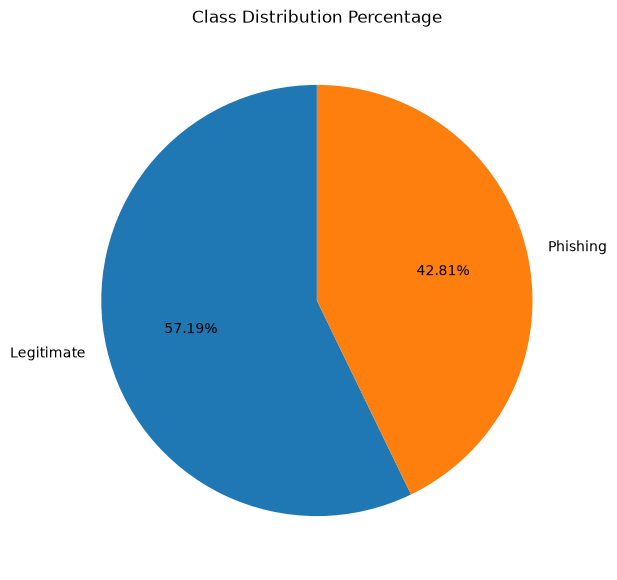

In [7]:
df['Class'] = df['target'].map({
    0: "Legitimate",
    1: "Phishing"
})

print(df['Class'].value_counts())

class_percent = (
    df["Class"]
    .value_counts(normalize=True)
    .mul(100)
)

plt.figure(figsize=(7, 7))

plt.pie(
    class_percent,
    labels=class_percent.index,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Class Distribution Percentage")
plt.show()

Our dataset is slight imbalanced, wherein the Legitimate is 57.19% and Phishing is 42.81%

In [8]:
exclude_cols = ['FILENAME', 'URL', 'Domain', 'Title', 'TLD', 'label', 'target', 'Class']

numeric_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in exclude_cols
]

print("Numerical Features: ", len(numeric_cols))
print(numeric_cols)

Numerical Features:  50
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


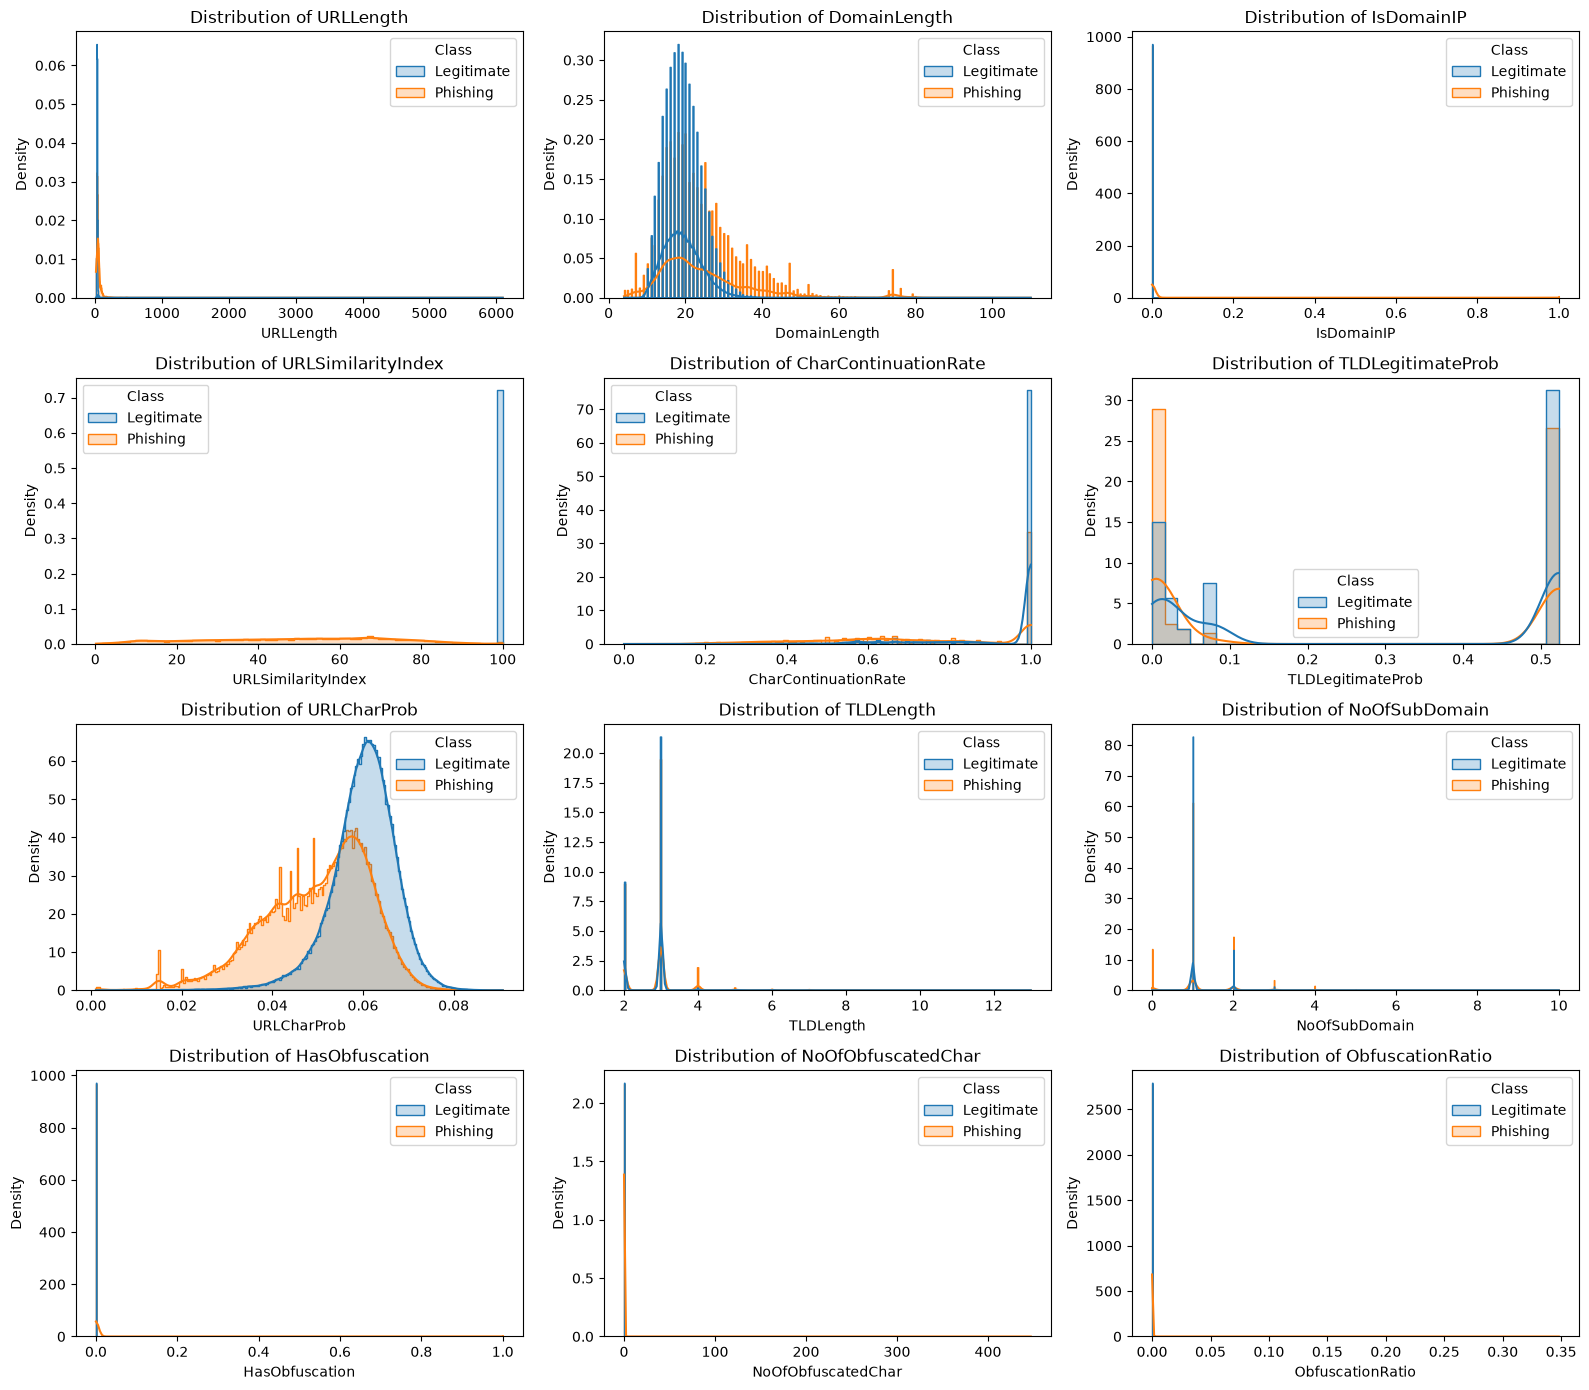

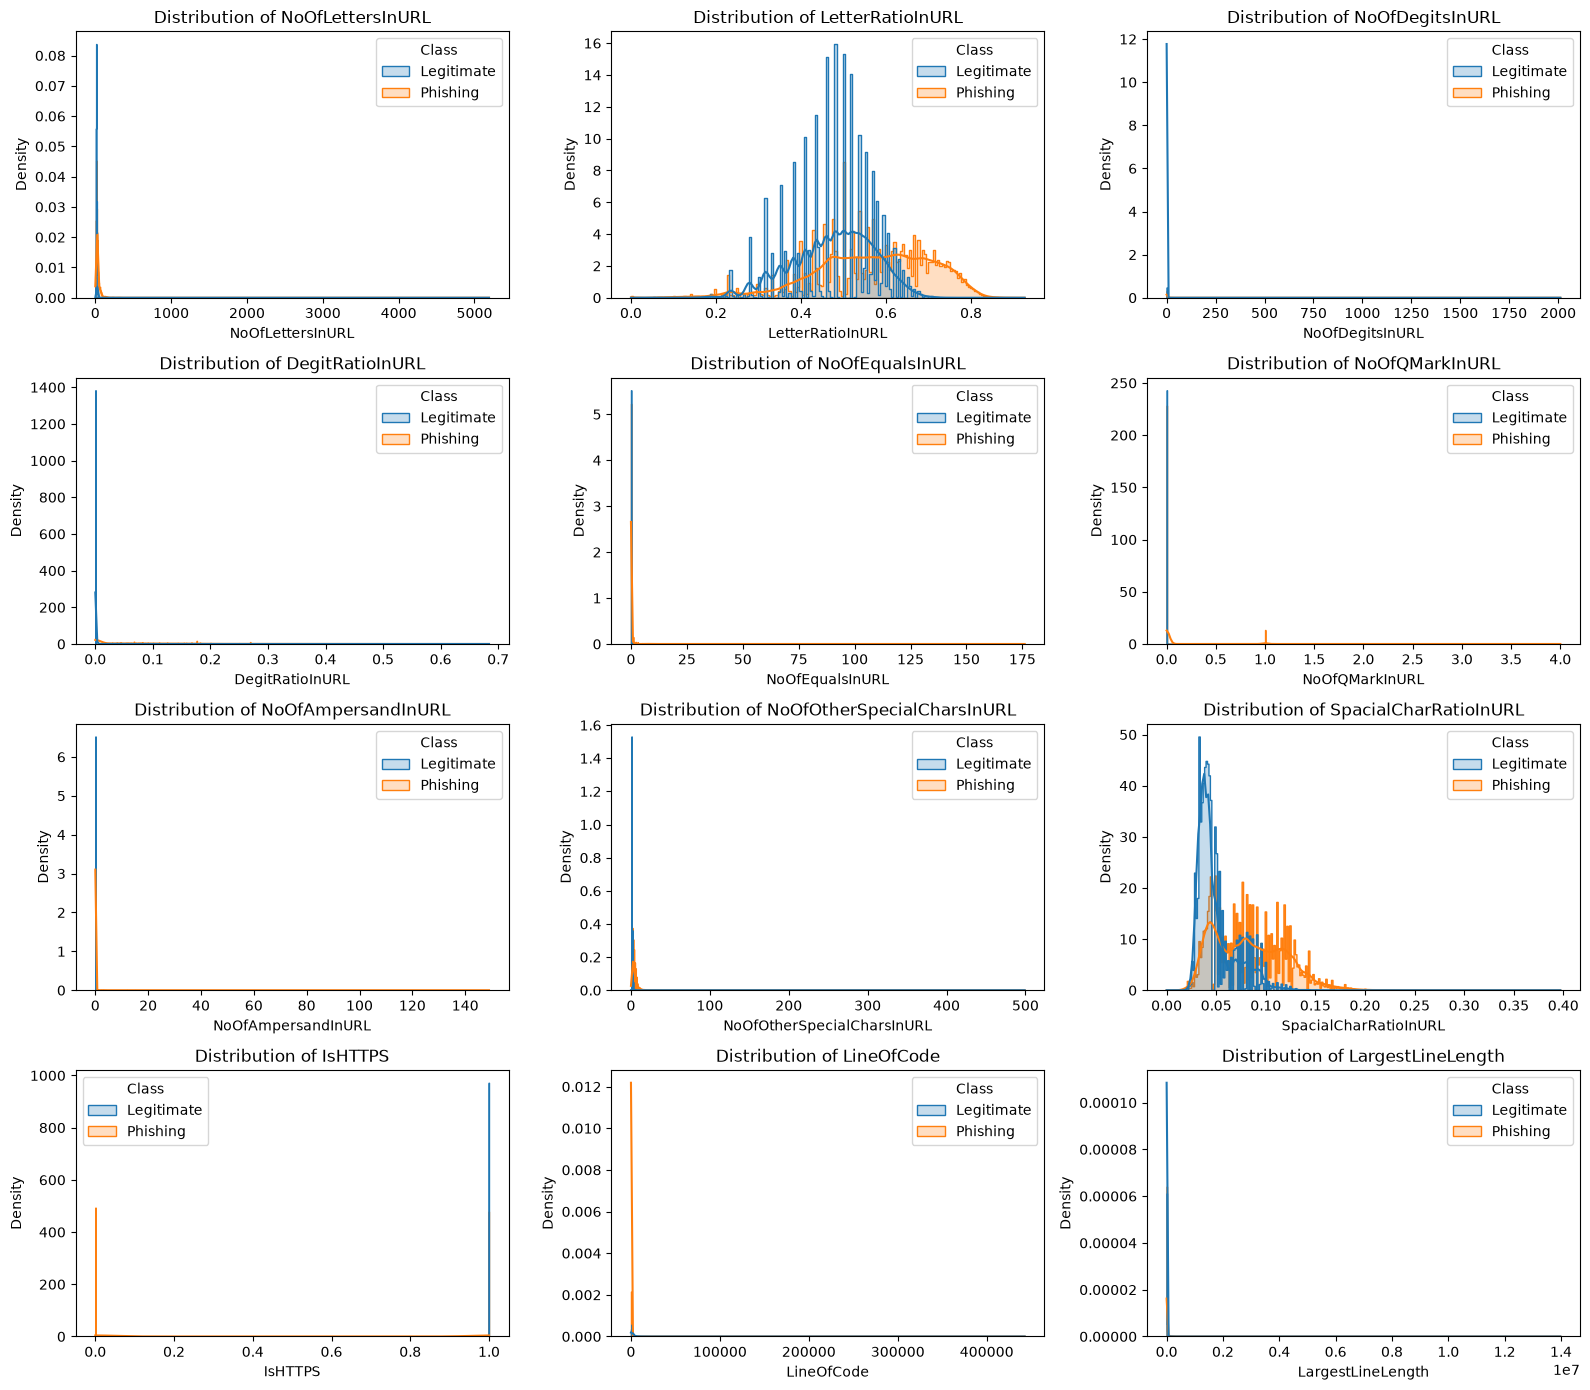

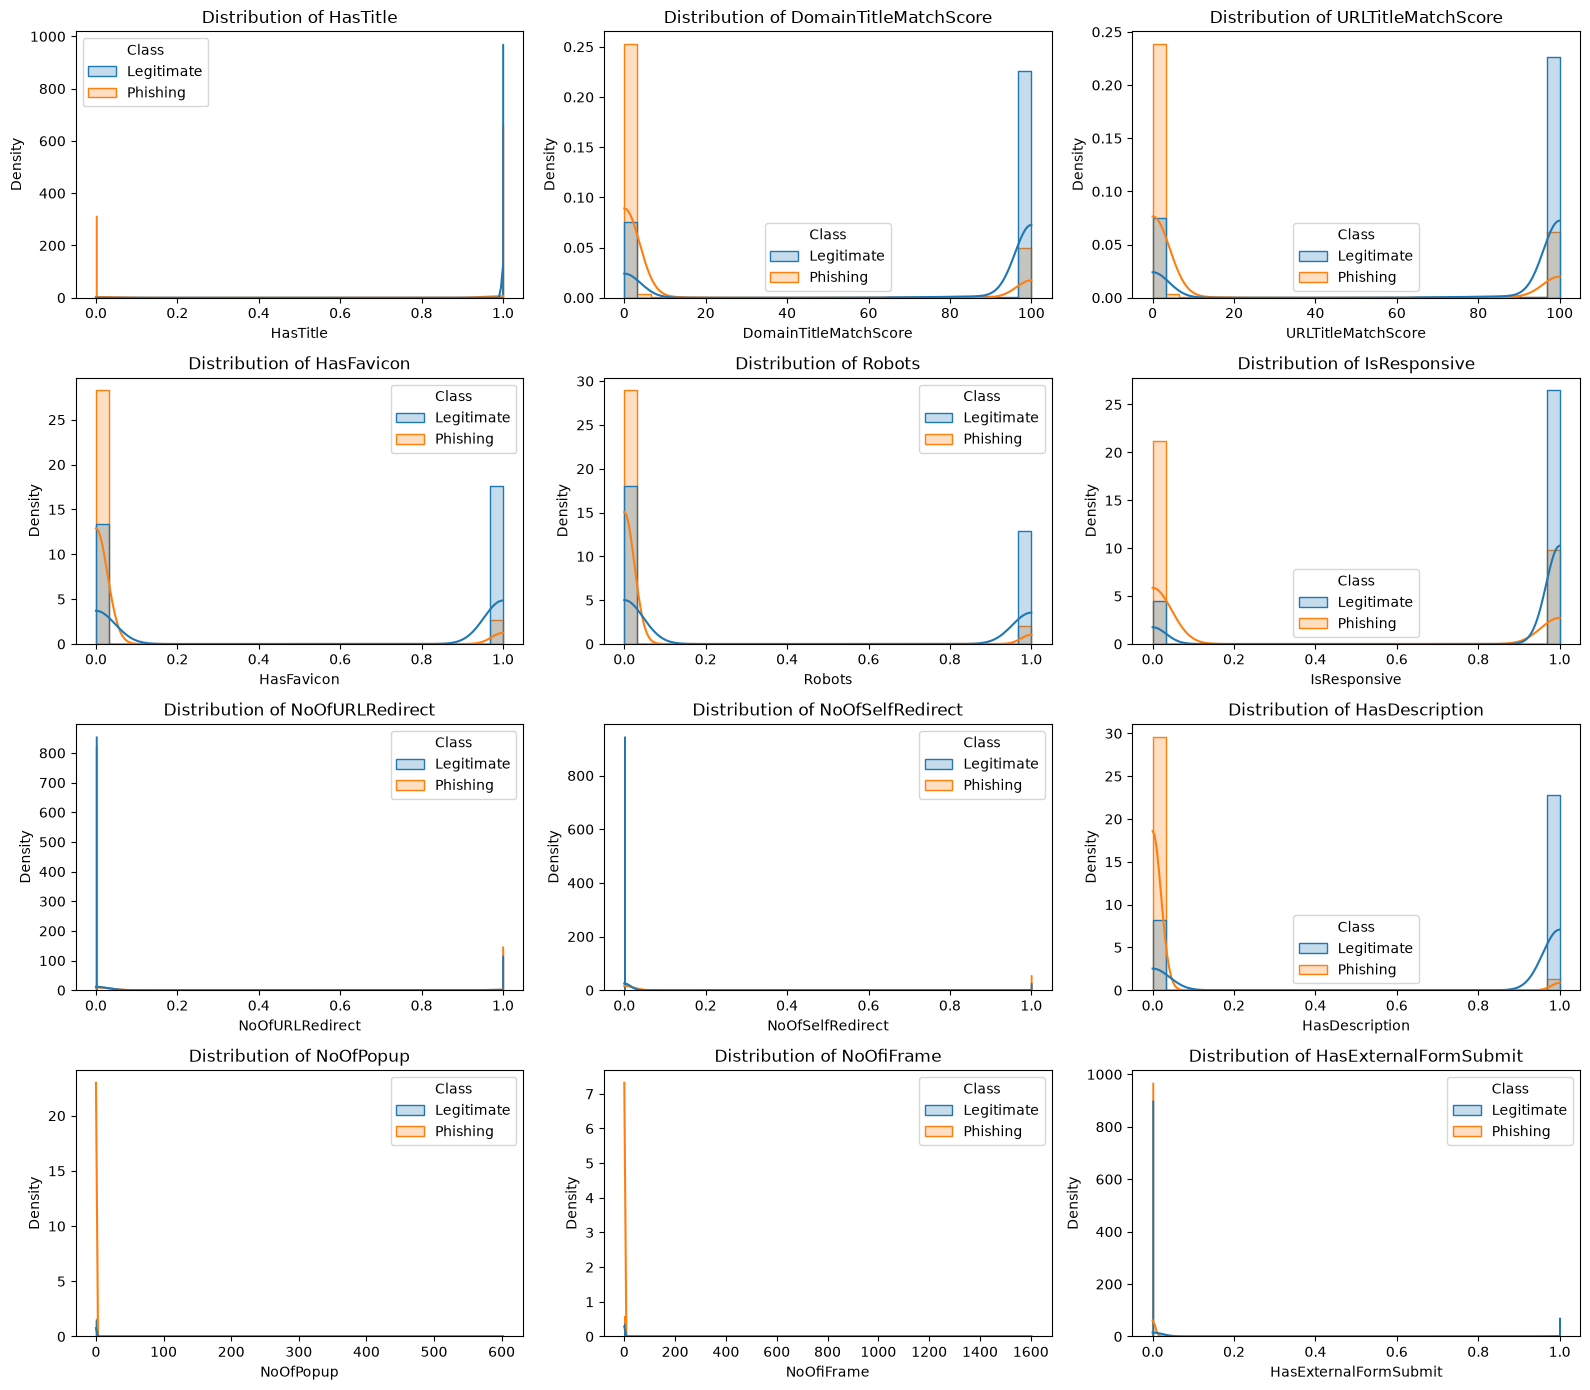

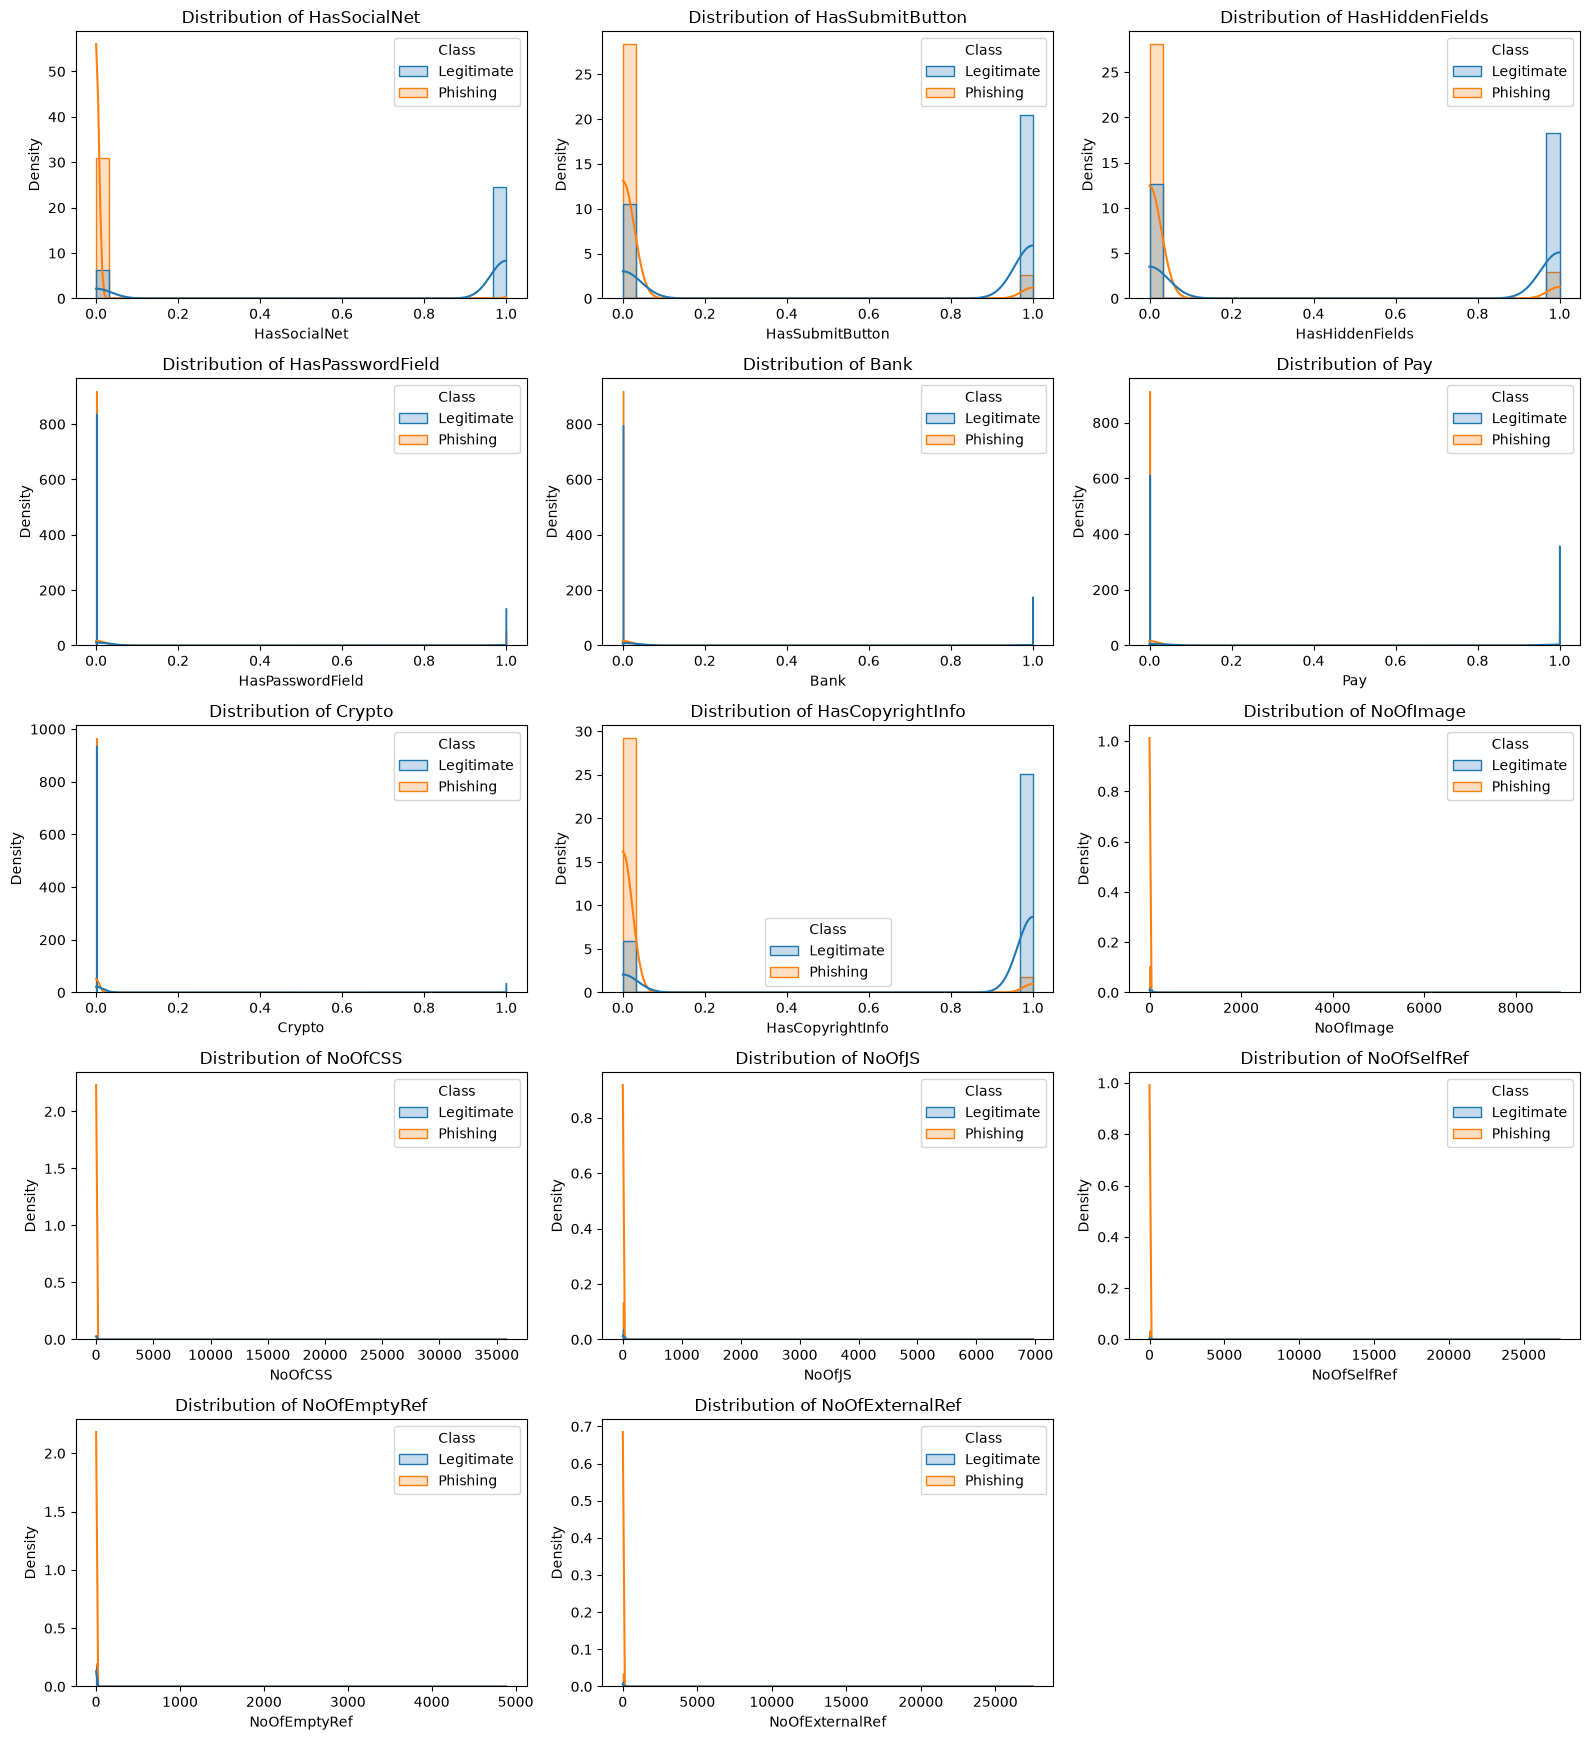

In [9]:
def plot_distributions(data, features, ncols=3):
    nrows = int(np.ceil(len(features) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3.5))
    axes = np.array(axes).flatten()

    for i, col in enumerate(features):
        sns.histplot(
            data=data,
            x = col,
            hue = 'Class',
            kde=True,
            stat='density',
            common_norm=False,
            ax=axes[i],
            element='step',
        )

        axes[i].set_title(f'Distribution of {col}')

    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()


plot_distributions(df, numeric_cols[:12])
plot_distributions(df, numeric_cols[12:24])
plot_distributions(df, numeric_cols[24:36])
plot_distributions(df, numeric_cols[36:])

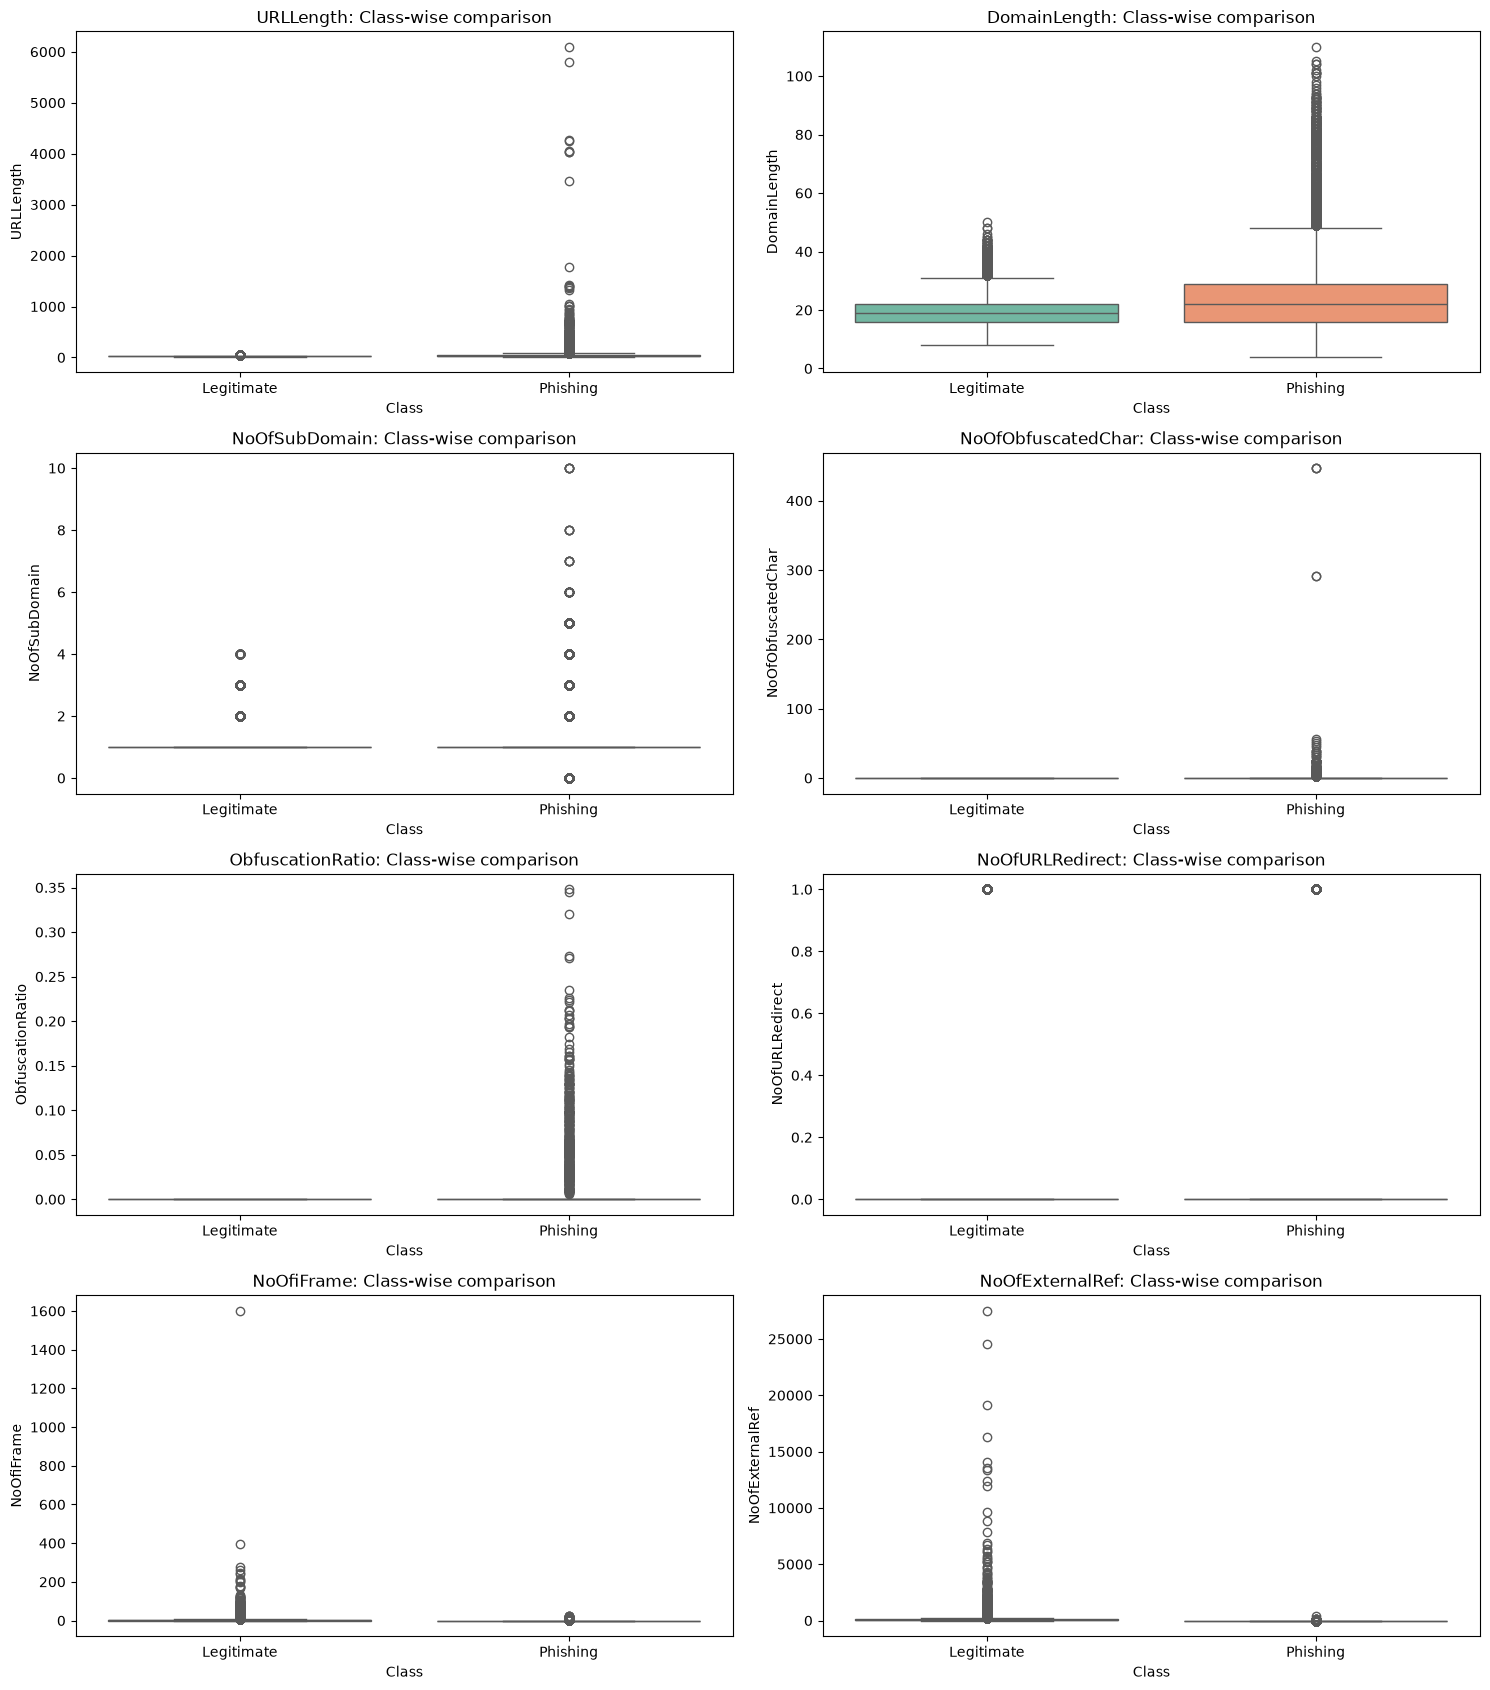

In [10]:
selected_features = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfURLRedirect",
    "NoOfiFrame",
    "NoOfExternalRef"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

for ax, col in zip(axes.flatten(), selected_features):

    sns.boxplot(
        data=df,
        x="Class",
        y=col,
        hue="Class",
        legend=False,
        ax=ax,
        palette="Set2"
    )

    ax.set_title(f"{col}: Class-wise comparison")

plt.tight_layout()
plt.show()

In [11]:
mean_comparison = (
    df.groupby("Class")[numeric_cols]
      .mean()
      .T
)

display(mean_comparison)

Class,Legitimate,Phishing
URLLength,26.228610,45.720293
DomainLength,19.228610,24.465144
IsDomainIP,0.000000,0.006320
URLSimilarityIndex,100.000000,49.616973
CharContinuationRate,0.933176,0.728395
TLDLegitimateProb,0.281625,0.232099
URLCharProb,0.060050,0.049999
TLDLength,2.723382,2.819327
NoOfSubDomain,1.161661,1.168894
HasObfuscation,0.000000,0.004805


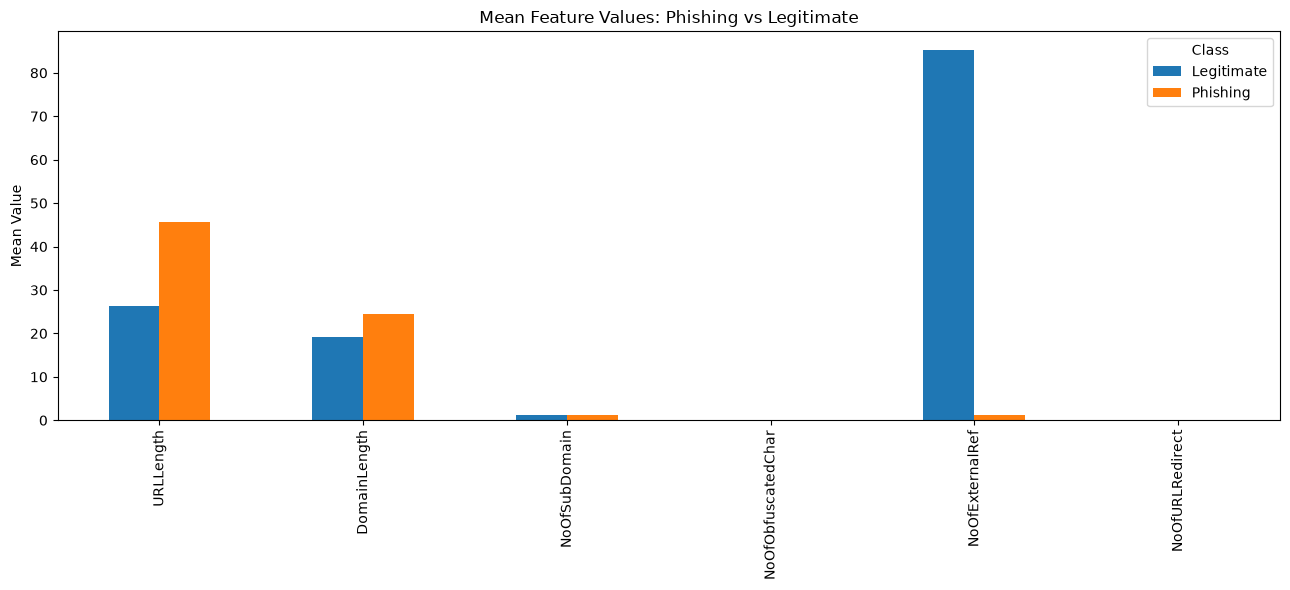

In [12]:
selected = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "NoOfExternalRef",
    "NoOfURLRedirect"
]

# Use .loc to select rows, and remove .T
mean_comparison.loc[selected].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Mean Feature Values: Phishing vs Legitimate")
plt.ylabel("Mean Value")
plt.tight_layout()
plt.show()

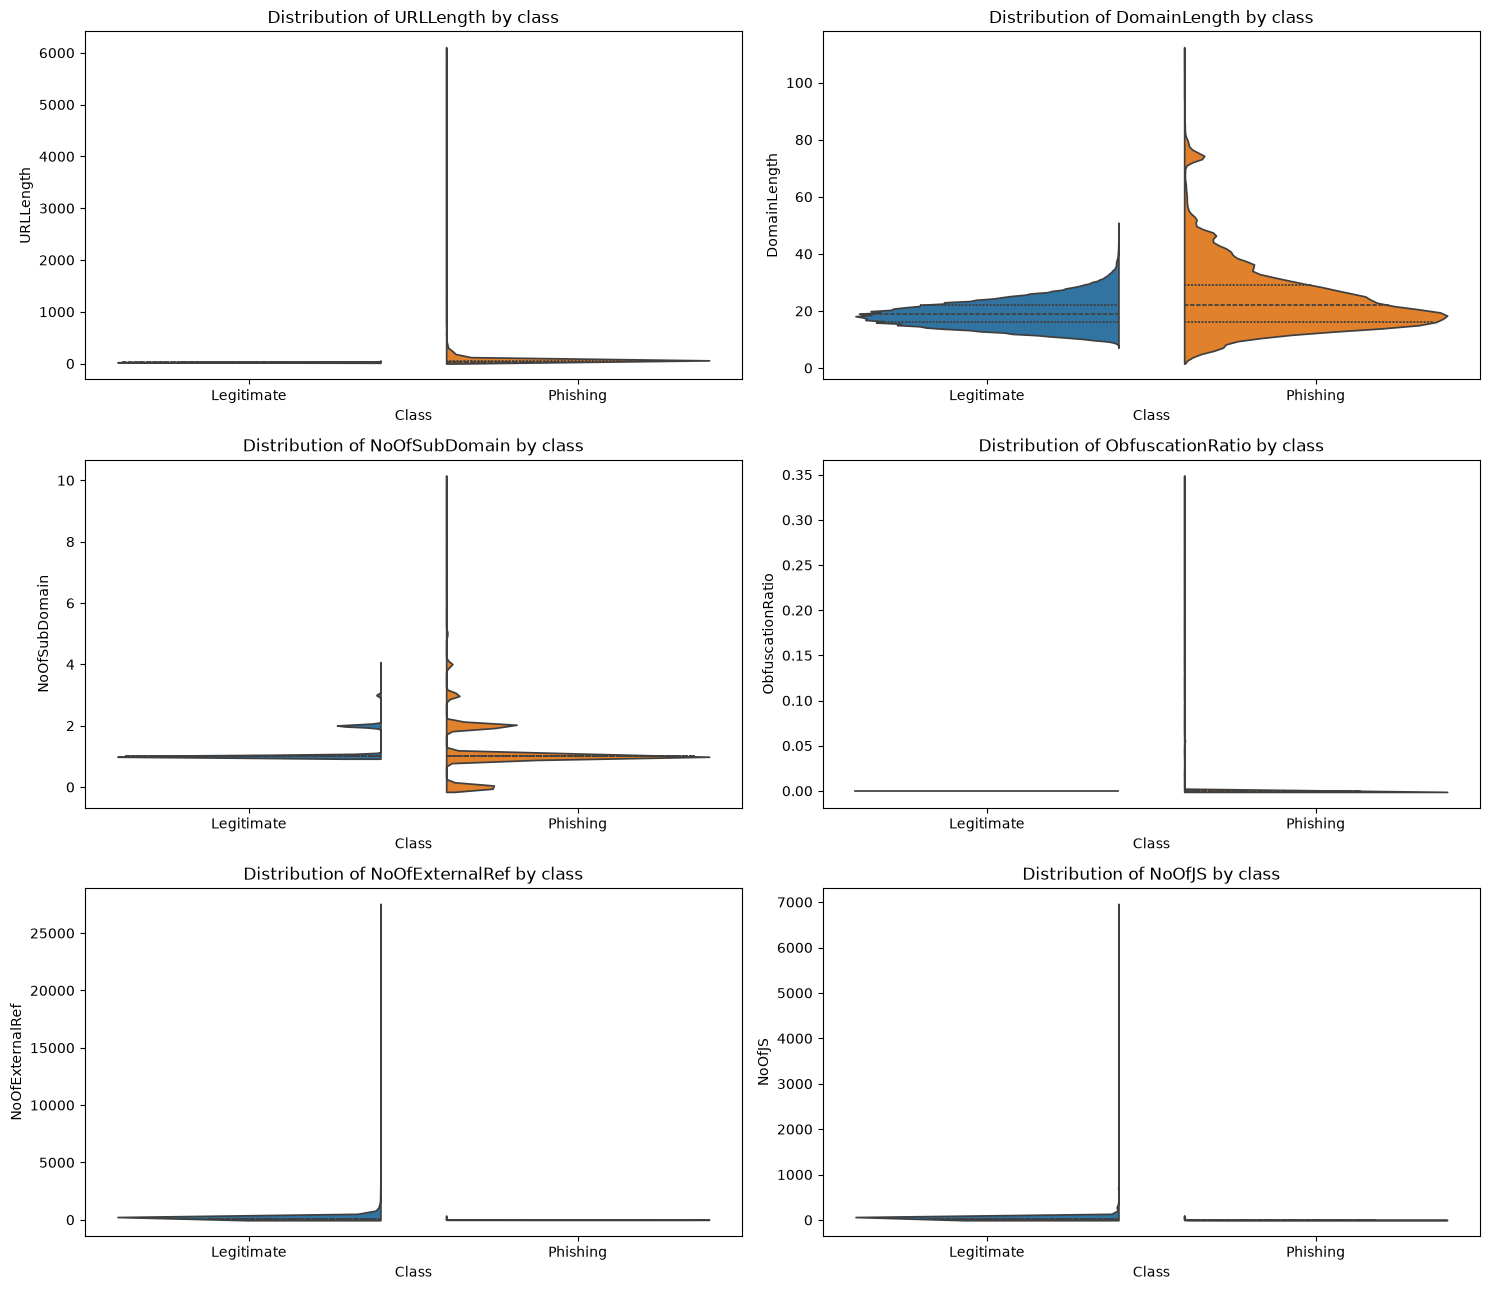

In [13]:
features = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "ObfuscationRatio",
    "NoOfExternalRef",
    "NoOfJS"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))

for ax, col in zip(axes.flatten(), features):

    sns.violinplot(
        data=df,
        x="Class",
        y=col,
        hue="Class",
        split=True,
        inner="quart",
        legend=False,
        ax=ax
    )

    ax.set_title(f"Distribution of {col} by class")

plt.tight_layout()
plt.show()

In [14]:
mean_comparison = (
    df.groupby("Class")[numeric_cols]
      .mean()
      .T
)
display(mean_comparison)

selected = [
    "URLLength",
    "DomainLength",
    "NoOfSubDomain",
    "NoOfObfuscatedChar",
    "NoOfExternalRef",
    "NoOfURLRedirect"
]

Class,Legitimate,Phishing
URLLength,26.228610,45.720293
DomainLength,19.228610,24.465144
IsDomainIP,0.000000,0.006320
URLSimilarityIndex,100.000000,49.616973
CharContinuationRate,0.933176,0.728395
TLDLegitimateProb,0.281625,0.232099
URLCharProb,0.060050,0.049999
TLDLength,2.723382,2.819327
NoOfSubDomain,1.161661,1.168894
HasObfuscation,0.000000,0.004805


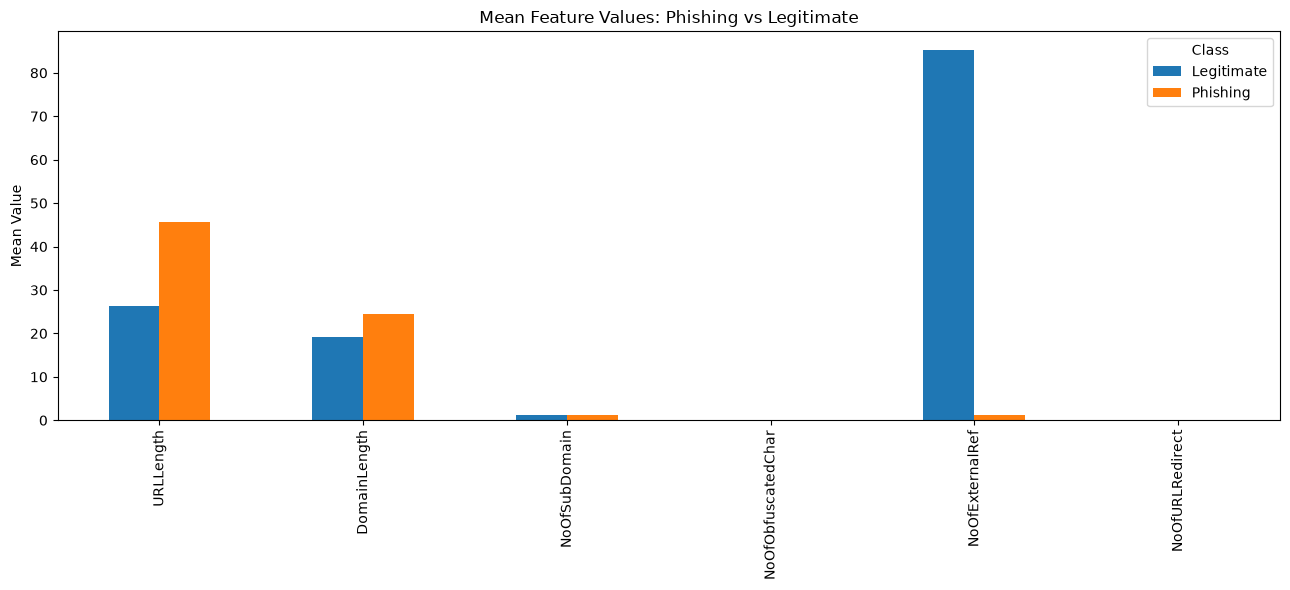

In [15]:
mean_comparison.loc[selected].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Mean Feature Values: Phishing vs Legitimate")
plt.ylabel("Mean Value")
plt.tight_layout()
plt.show()

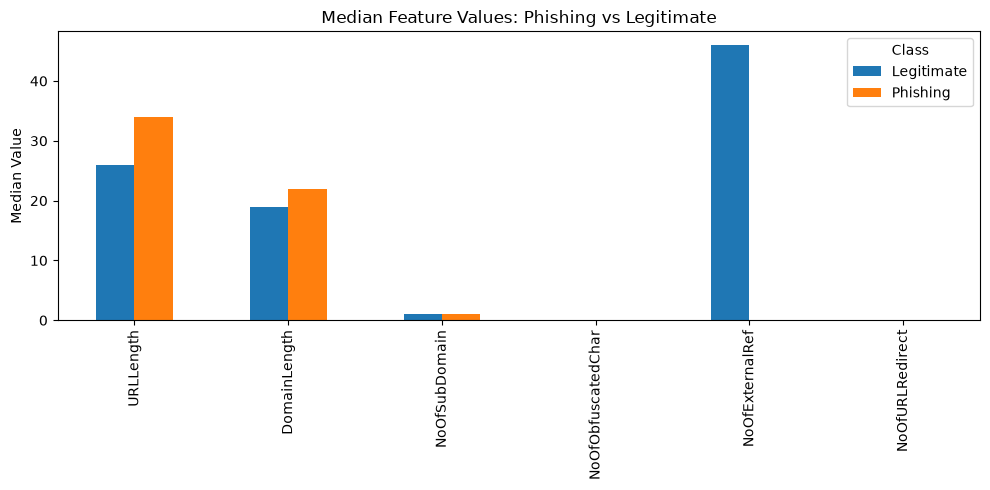

In [16]:
median_comparison = (
    df.groupby("Class")[numeric_cols]
      .median()
      .T
)

median_comparison.loc[selected].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Median Feature Values: Phishing vs Legitimate")
plt.ylabel("Median Value")
plt.tight_layout()
plt.show()

#### Plot 8: Binary Feature Prevalance

In [17]:
binary_cols = [
    col for col in numeric_cols
    if df[col].nunique(dropna=True) == 2
]

print(binary_cols)

['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo']


In [18]:
binary_rates = (
    df.groupby("Class")[binary_cols]
      .mean()
      .T * 100
)

display(binary_rates)

Class,Legitimate,Phishing
IsDomainIP,0.000000,0.632027
HasObfuscation,0.000000,0.480460
IsHTTPS,100.000000,49.223835
HasTitle,99.875417,67.758680
HasFavicon,56.702262,8.757244
Robots,41.673712,6.589727
IsResponsive,85.436411,31.746000
NoOfURLRedirect,11.977011,15.169647
NoOfSelfRedirect,2.712644,5.744712
HasDescription,73.663330,4.416266


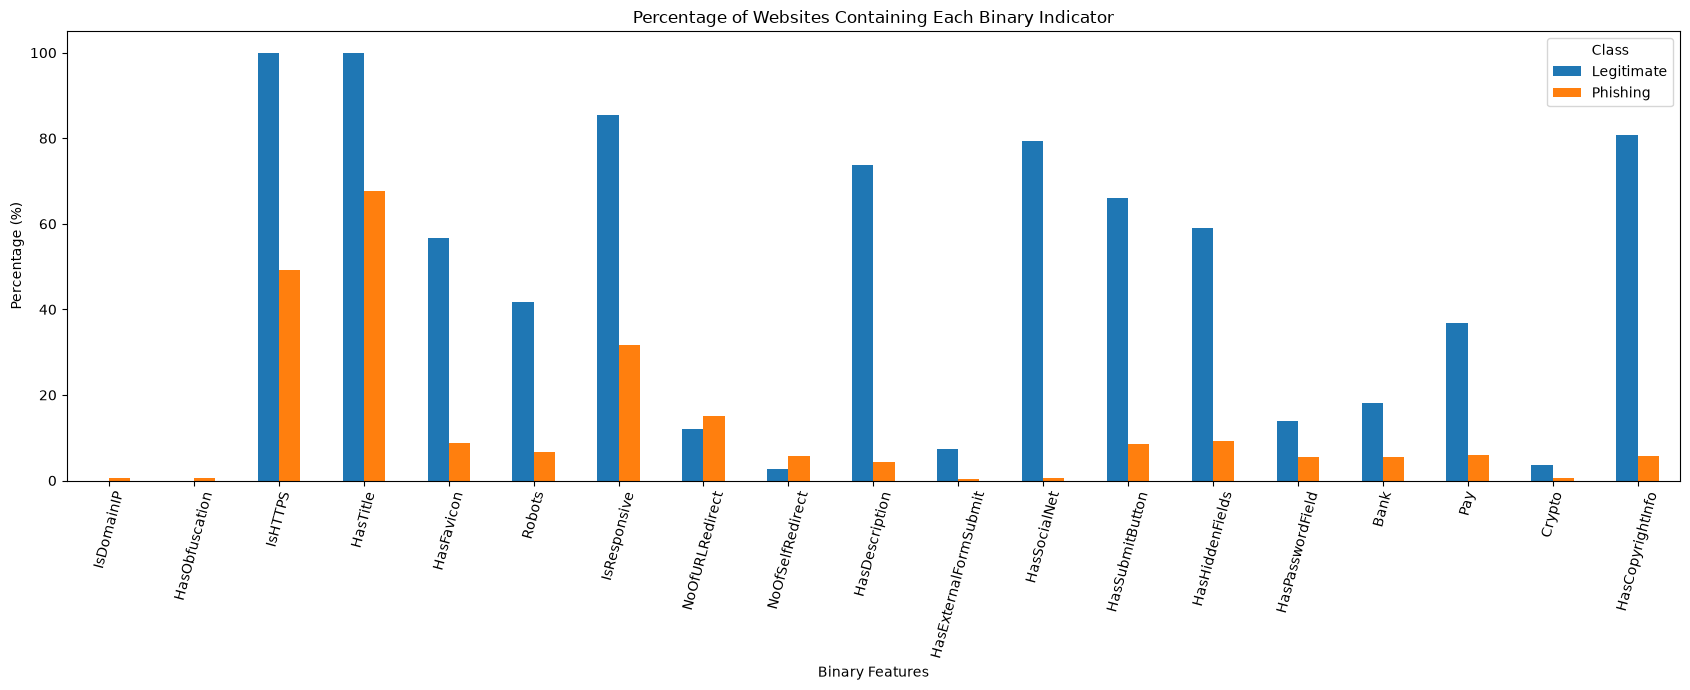

In [19]:
binary_rates.plot(
    kind="bar",
    figsize=(17, 7)
)

plt.title("Percentage of Websites Containing Each Binary Indicator")
plt.ylabel("Percentage (%)")
plt.xlabel("Binary Features")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

#### Plot 9 - TLD Analysis

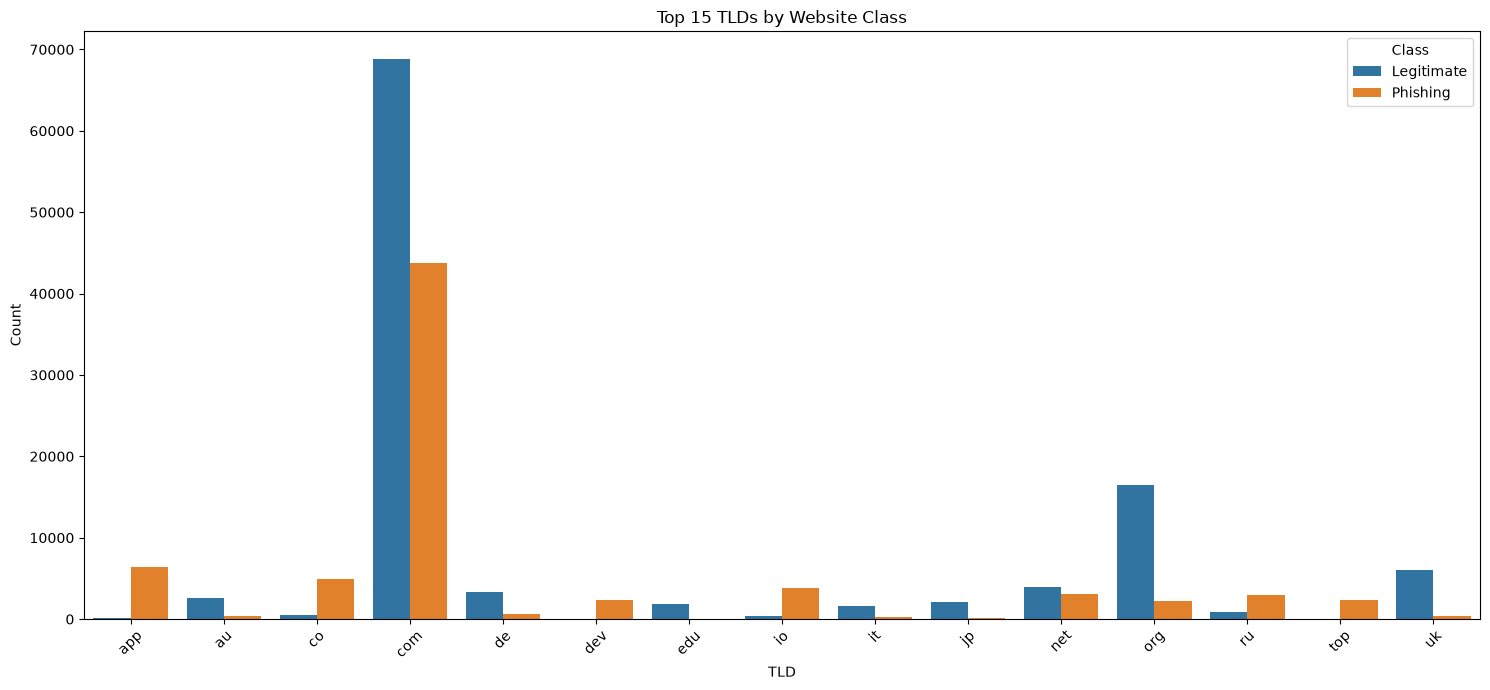

In [20]:
tld_counts = (
    df.groupby(["TLD", "Class"])
      .size()
      .reset_index(name="Count")
)

top_tlds = (
    df["TLD"]
    .value_counts()
    .head(15)
    .index
)

tld_data = tld_counts[
    tld_counts["TLD"].isin(top_tlds)
]

plt.figure(figsize=(15, 7))

sns.barplot(
    data=tld_data,
    x="TLD",
    y="Count",
    hue="Class"
)

plt.title("Top 15 TLDs by Website Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
tld_risk = (
    df.groupby("TLD")["target"]
      .agg(["mean", "count"])
      .rename(columns={"mean": "Phishing_Rate"})
)

tld_risk = tld_risk[
    tld_risk["count"] >= 100
].sort_values("Phishing_Rate", ascending=False)

display(tld_risk.head(15))

,Phishing_Rate,count
TLD,,
cfd,1.000000,107
cf,1.000000,1203
gq,1.000000,493
icu,1.000000,151
page,1.000000,490
top,0.999141,2329
ml,0.998995,995
site,0.996626,1482
ga,0.996400,1111


### Correlation Analysis

#### Plot 10: Spearman correlation heatmap

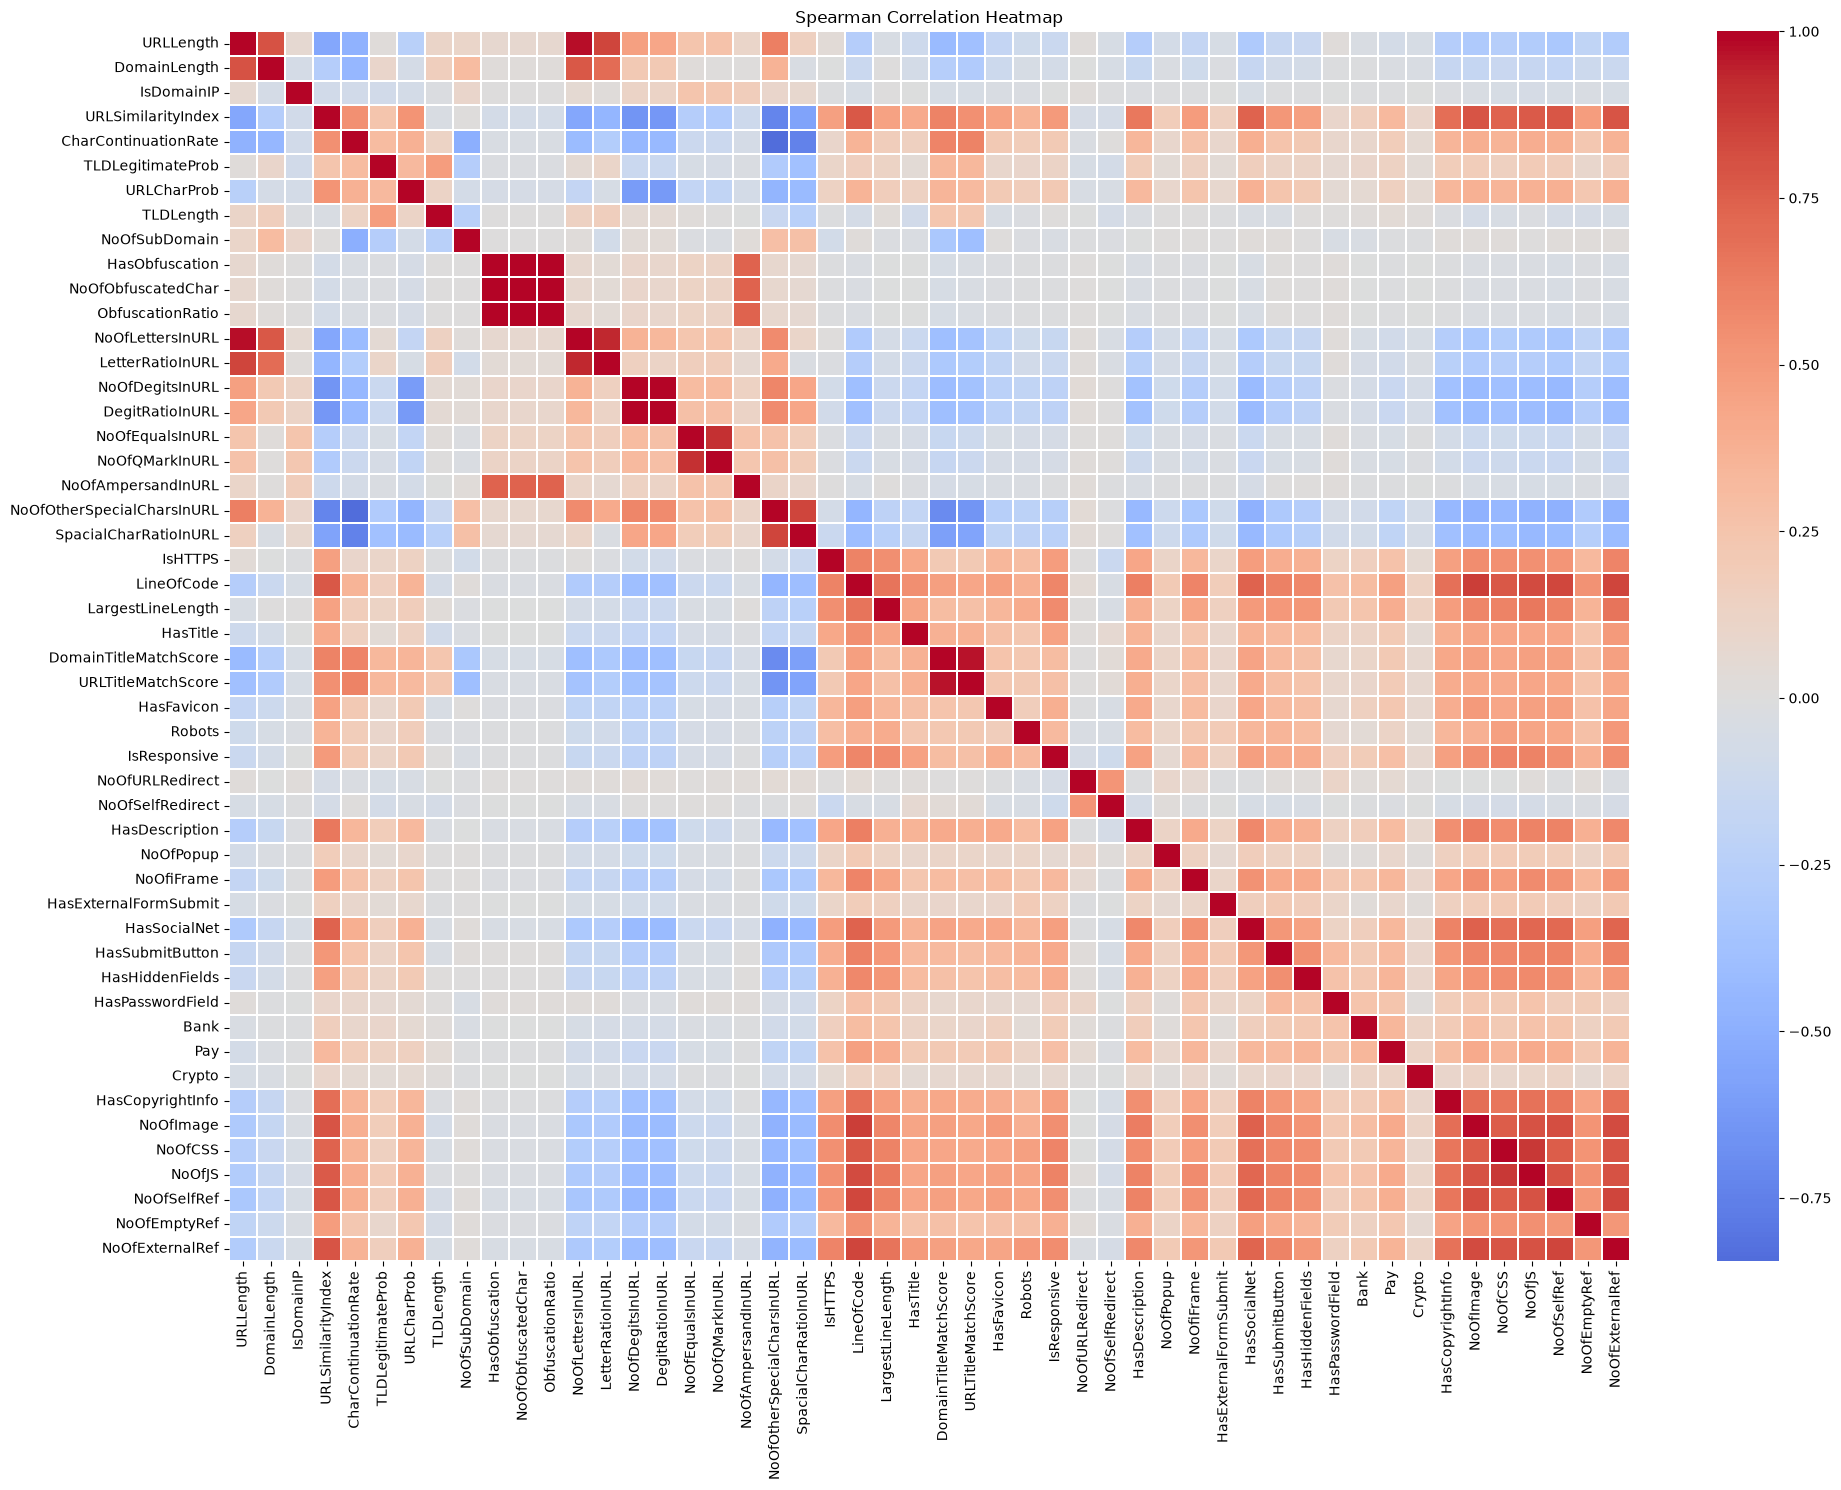

In [22]:
corr_matrix = df[numeric_cols].corr(
    method="spearman"
)

plt.figure(figsize=(20, 15))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)

plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.show()

#### Plot 11 - Feature Correlation with Phishing Target

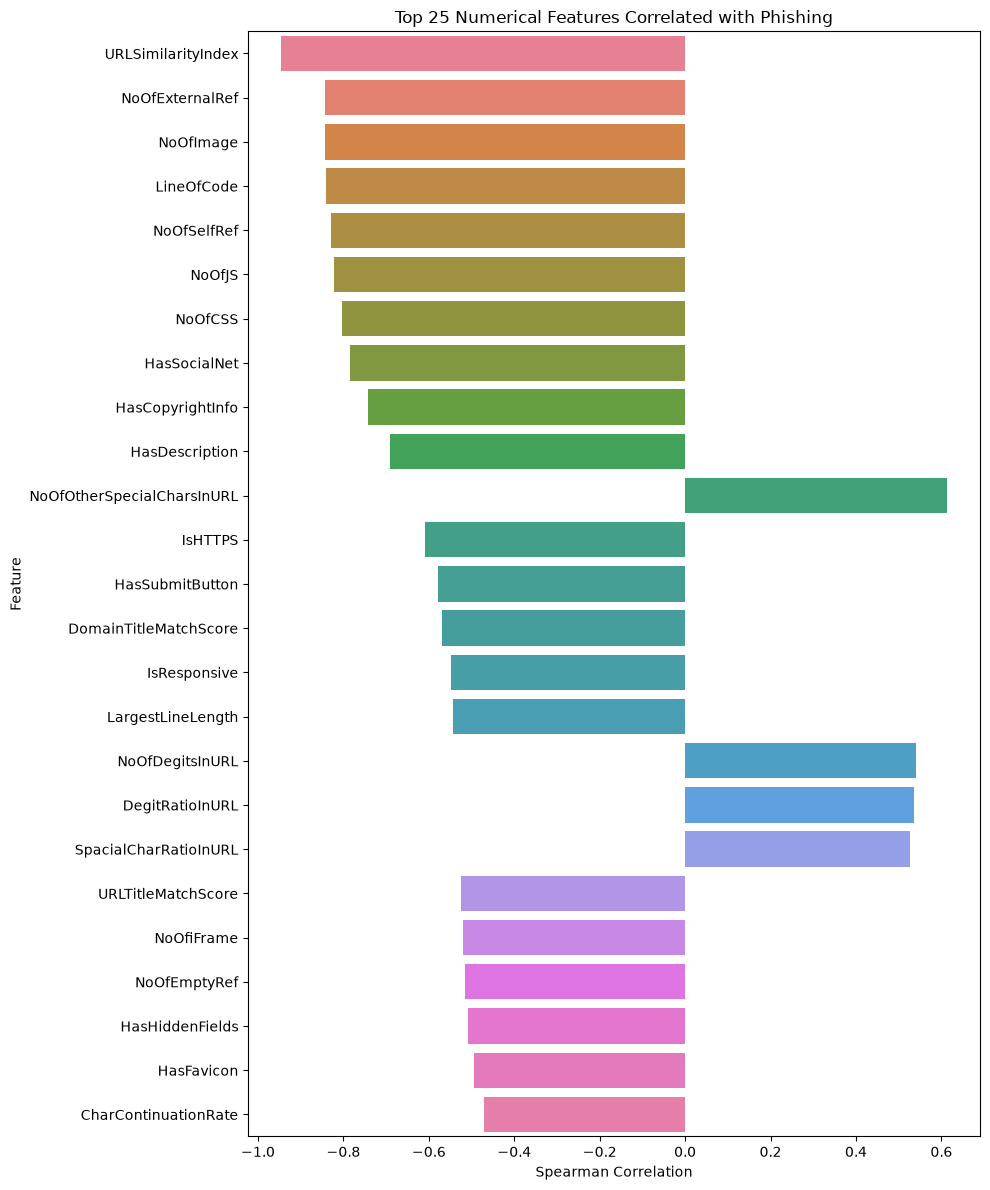

In [23]:
target_corr = (
    df[numeric_cols + ["target"]]
    .corr(method="spearman")["target"]
    .drop("target")
    .sort_values(key=abs, ascending=False)
)

plt.figure(figsize=(10, 12))

sns.barplot(
    x=target_corr.values[:25],
    y=target_corr.index[:25],
    hue=target_corr.index[:25],
    legend=False
)

plt.title("Top 25 Numerical Features Correlated with Phishing")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Outlier Analysis

#### Plot 12 - IQR-based outlier analysis

In [24]:
outlier_results = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier_Count": count,
        "Outlier_Percentage": count / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
    "Outlier_Percentage",
    ascending=False
)

display(outlier_df)

,Feature,Outlier_Count,Outlier_Percentage
8,NoOfSubDomain,57389,24.338514
41,Pay,55885,23.700672
14,NoOfDegitsInURL,51461,21.824466
15,DegitRatioInURL,51461,21.824466
21,IsHTTPS,51256,21.737526
48,NoOfEmptyRef,38885,16.491020
34,NoOfiFrame,34441,14.606332
24,HasTitle,32714,13.873916
30,NoOfURLRedirect,31464,13.343794
40,Bank,29967,12.708921


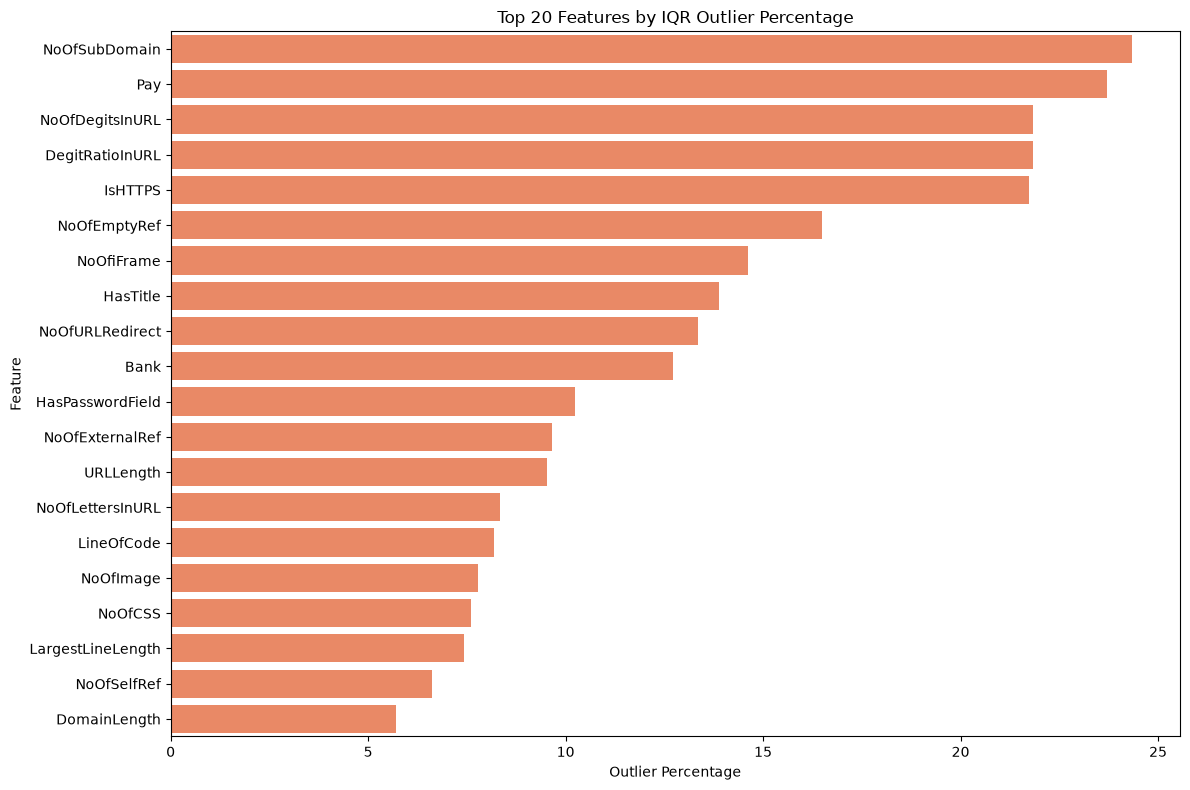

In [25]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=outlier_df.head(20),
    x="Outlier_Percentage",
    y="Feature",
    color='coral'
)

plt.title("Top 20 Features by IQR Outlier Percentage")
plt.xlabel("Outlier Percentage")
plt.tight_layout()
plt.show()

### Feature interaction analysis

#### Plot 13 - Password Field vs External Form Submission

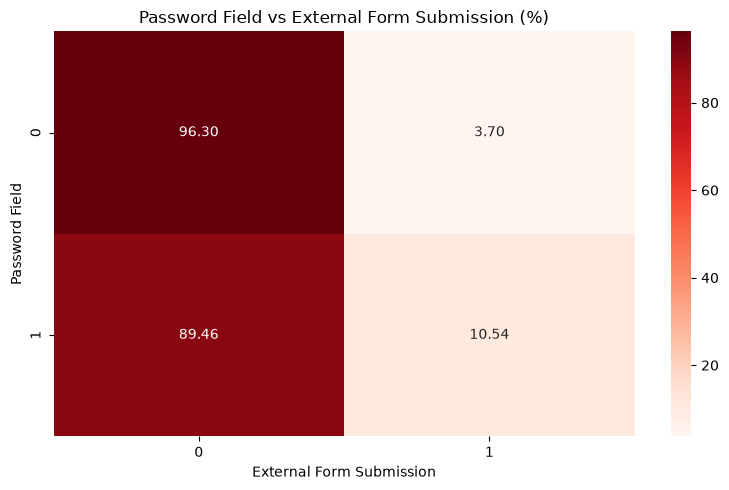

In [26]:
interaction = pd.crosstab(
    df["HasPasswordField"],
    df["HasExternalFormSubmit"],
    normalize="index"
) * 100

plt.figure(figsize=(8, 5))

sns.heatmap(
    interaction,
    annot=True,
    fmt=".2f",
    cmap="Reds"
)

plt.title(
    "Password Field vs External Form Submission (%)"
)

plt.xlabel("External Form Submission")
plt.ylabel("Password Field")

plt.tight_layout()
plt.show()

#### Plot 14 - Three Way Interaction

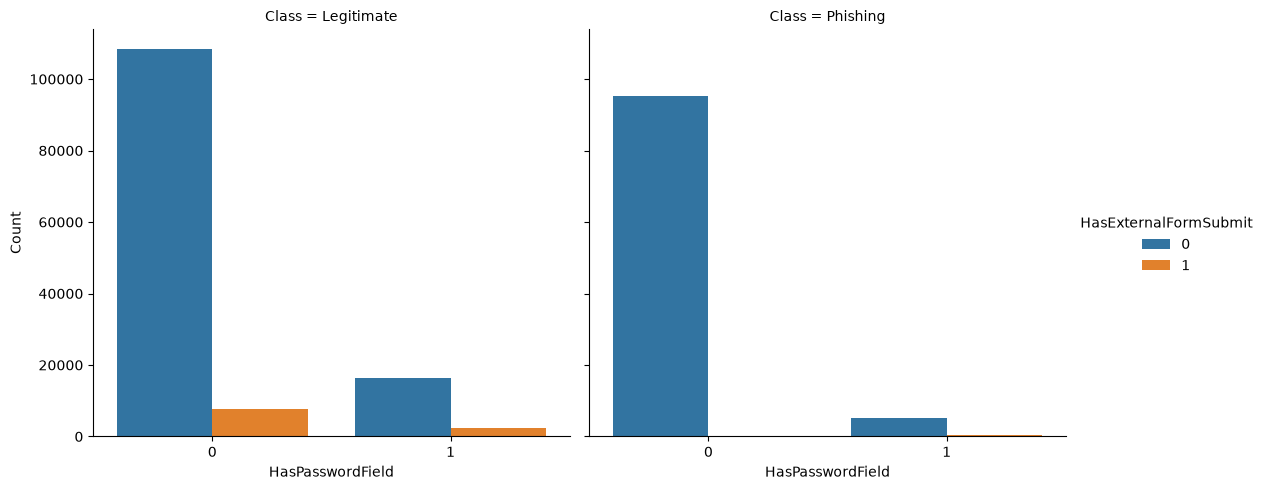

In [27]:
interaction_data = (
    df.groupby([
        "HasPasswordField",
        "HasExternalFormSubmit",
        "Class"
    ])
    .size()
    .reset_index(name="Count")
)

sns.catplot(
    data=interaction_data,
    x="HasPasswordField",
    y="Count",
    hue="HasExternalFormSubmit",
    col="Class",
    kind="bar",
    height=5,
    aspect=1.1
)

plt.show()

#### Plot 15 - Domain-title mismatch vs URL similarity

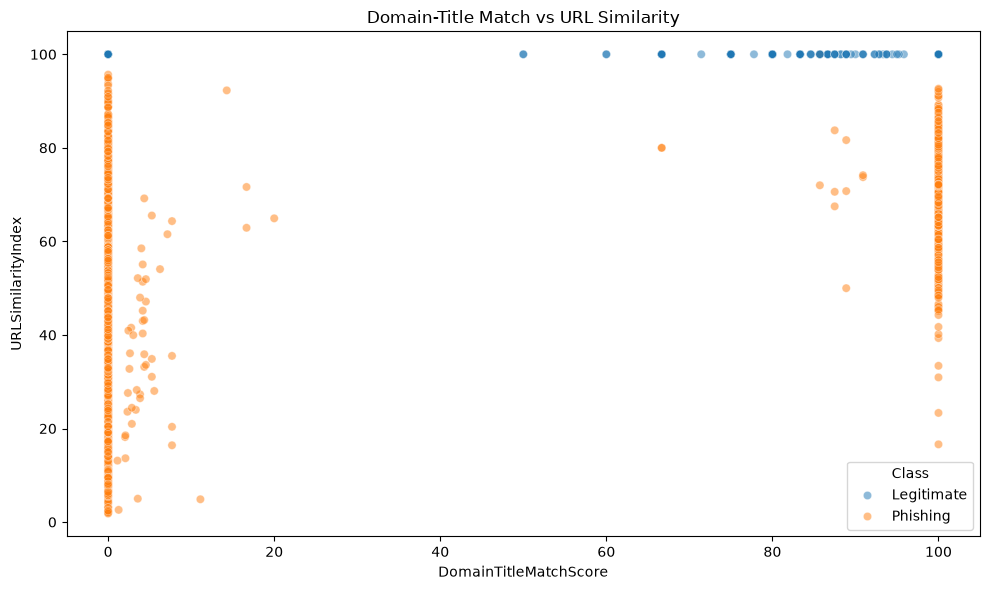

In [28]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df.sample(
        min(5000, len(df)),
        random_state=42
    ),
    x="DomainTitleMatchScore",
    y="URLSimilarityIndex",
    hue="Class",
    alpha=0.5
)

plt.title(
    "Domain-Title Match vs URL Similarity"
)

plt.tight_layout()
plt.show()

### Statistical significance testing

#### Plot 16 - Statistical comparison

In [29]:
import scipy.stats as stats

phishing = df[df["target"] == 1]
legitimate = df[df["target"] == 0]

statistical_results = []

for col in numeric_cols:
    x = phishing[col].dropna()
    y = legitimate[col].dropna()

    if x.nunique() <= 1 and y.nunique() <= 1:
        continue

    stat, p_value = stats.mannwhitneyu(
        x,
        y,
        alternative="two-sided"
    )

    statistical_results.append({
        "Feature": col,
        "Phishing_Median": x.median(),
        "Legitimate_Median": y.median(),
        "P_Value": p_value
    })

stats_df = pd.DataFrame(statistical_results)

# Multiple testing correction
from statsmodels.stats.multitest import multipletests

stats_df["Adjusted_P_Value"] = multipletests(
    stats_df["P_Value"],
    method="fdr_bh"
)[1]

stats_df["Significant"] = (
    stats_df["Adjusted_P_Value"] < 0.05
)

stats_df = stats_df.sort_values(
    "Adjusted_P_Value"
)

display(stats_df)

,Feature,Phishing_Median,Legitimate_Median,P_Value,Adjusted_P_Value,Significant
0,URLLength,34.000000,26.000000,0.000000e+00,0.000000e+00,True
1,DomainLength,22.000000,19.000000,0.000000e+00,0.000000e+00,True
3,URLSimilarityIndex,51.419332,100.000000,0.000000e+00,0.000000e+00,True
4,CharContinuationRate,0.727273,1.000000,0.000000e+00,0.000000e+00,True
6,URLCharProb,0.052023,0.060628,0.000000e+00,0.000000e+00,True
5,TLDLegitimateProb,0.018013,0.522907,0.000000e+00,0.000000e+00,True
14,NoOfDegitsInURL,0.000000,0.000000,0.000000e+00,0.000000e+00,True
15,DegitRatioInURL,0.000000,0.000000,0.000000e+00,0.000000e+00,True
13,LetterRatioInURL,0.577000,0.480000,0.000000e+00,0.000000e+00,True
12,NoOfLettersInURL,20.000000,13.000000,0.000000e+00,0.000000e+00,True


### Consolidated EDA Report

#### Plot {} - Feature statistics by class

In [30]:
summary = df.groupby("Class")[numeric_cols].agg(
    ["mean", "median", "std", "min", "max"]
)

display(summary.T)

Class                     Legitimate     Phishing
URLLength       mean       26.228610    45.720293
                median     26.000000    34.000000
                std         4.815612    61.145523
                min        15.000000    13.000000
                max        57.000000  6097.000000
...                              ...          ...
NoOfExternalRef mean       85.294601     1.128119
                median     46.000000     0.000000
                std       205.669475     3.204587
                min         0.000000     0.000000
                max     27516.000000   368.000000

[250 rows x 2 columns]

In [31]:
comparison = pd.DataFrame({
    "Phishing_Mean": df[df["target"] == 1][numeric_cols].mean(),
    "Legitimate_Mean": df[df["target"] == 0][numeric_cols].mean(),

    "Phishing_Median": df[df["target"] == 1][numeric_cols].median(),
    "Legitimate_Median": df[df["target"] == 0][numeric_cols].median(),

    "Phishing_Std": df[df["target"] == 1][numeric_cols].std(),
    "Legitimate_Std": df[df["target"] == 0][numeric_cols].std()
})

display(comparison)

,Phishing_Mean,Legitimate_Mean,Phishing_Median,Legitimate_Median,Phishing_Std,Legitimate_Std
URLLength,45.720293,26.228610,34.000000,26.000000,61.145523,4.815612
DomainLength,24.465144,19.228610,22.000000,19.000000,12.204054,4.815612
IsDomainIP,0.006320,0.000000,0.000000,0.000000,0.079249,0.000000
URLSimilarityIndex,49.616973,100.000000,51.419332,100.000000,22.572082,0.000000
CharContinuationRate,0.728395,0.933176,0.727273,1.000000,0.243976,0.139818
TLDLegitimateProb,0.232099,0.281625,0.018013,0.522907,0.254775,0.247132
URLCharProb,0.049999,0.060050,0.052023,0.060628,0.011634,0.007171
TLDLength,2.819327,2.723382,3.000000,3.000000,0.691359,0.516913
NoOfSubDomain,1.168894,1.161661,1.000000,1.000000,0.790880,0.404076
HasObfuscation,0.004805,0.000000,0.000000,0.000000,0.069149,0.000000
